# Final Adaptive Teacher: Reproducible Foggy Cityscapes Evaluation

**Local platform:** Apple Silicon M4 / CPU-first, Python virtual environment.  
**Model:** Final `adaptive_teacher_080/model_final.pth`, iteration **4,999**.  
**Verified checkpoint SHA256:** `bc37e39a71c468bc40b77cadb66d7aba6c1e6042eecf7446c94d40e14da0e1bd`.

## Scope and research integrity

This notebook preserves the *verified* model-building and checkpoint-loading sequence, then tests actual inference and evaluates identical scenes across **light, medium, strong** fog at score thresholds **0.80 / 0.70 / 0.60**. The checkpoint has been loaded with **113 teacher tensors, zero missing and zero unexpected keys** in the user's terminal. **Saved notebook outputs document completed local inference and evaluation.** Re-running requires the original local data, source code, checkpoint and Python environment. Inspect the saved evidence before rerunning.

**Important:** `SEMISUPNET.BBOX_THRESHOLD=0.8` is a *training pseudo-label threshold*. The three evaluation thresholds below are *inference detection-score cutoffs*. They are not interchangeable.

Run cells in order. No training or checkpoint modifications occur. Outputs are saved in a new results directory. CPU inference may be slow. Paths refer to the original Mac research workspace and must be checked on another machine.

## 1. Environment and paths

Use the existing `.venv` as your Jupyter kernel. If necessary, from a Terminal with `.venv` activated run `python -m pip install notebook ipykernel pandas matplotlib pillow pyyaml` and `python -m ipykernel install --user --name adaptive-teacher-m4 --display-name "Adaptive Teacher (M4)"`. Select that kernel in Jupyter. The notebook does **not** install or rebuild Detectron2.

In [1]:
import os, sys, json, time, hashlib, platform, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path.home() / 'Desktop/phd/vizuara/Deliverables/milestone2'
EXP = ROOT / 'Adaptive_teacher_Experiment 2'
REPO = EXP / 'research_code_results/adaptive_teacher_recovered/adaptive_teacher'
D2 = ROOT / 'detectron2'
CONFIG = EXP / 'research_code_results/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_v1/config.yaml'
CHECKPOINT = EXP / 'final_model_checkpoints/adaptive_teacher_080/model_final.pth'
OUT = EXP / 'local_final_teacher_evaluation'
OUT.mkdir(parents=True, exist_ok=True)
for p in [D2, REPO]:
    if str(p) not in sys.path: sys.path.insert(0, str(p))
for name,p in [('Detectron2',D2),('Adaptive Teacher source',REPO),('Config',CONFIG),('Checkpoint',CHECKPOINT)]:
    assert p.exists(), f'{name} missing: {p}'
print('Python:',sys.version.split()[0], '| Torch:',torch.__version__)
print('Platform:',platform.platform(), '| MPS available:',torch.backends.mps.is_available())
print('Output:',OUT)

Python: 3.10.10 | Torch: 2.5.1
Platform: macOS-26.6.2-arm64-arm-64bit | MPS available: True
Output: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/local_final_teacher_evaluation


## 2. Validate checkpoint identity and teacher branch

Loading the checkpoint uses `weights_only=False` because the trusted local training checkpoint includes optimizer/scheduler state. **Only load checkpoints you trust**; Python pickle loading can execute code.

In [2]:
EXPECTED_SHA256 = 'bc37e39a71c468bc40b77cadb66d7aba6c1e6042eecf7446c94d40e14da0e1bd'
def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()
actual_hash=sha256_file(CHECKPOINT)
print('SHA256:',actual_hash)
assert actual_hash==EXPECTED_SHA256, 'Checkpoint hash differs from verified final checkpoint; stop and investigate.'
checkpoint=torch.load(CHECKPOINT,map_location='cpu',weights_only=False)
print('Iteration:',checkpoint.get('iteration'))
assert checkpoint.get('iteration')==4999
model_keys=list(checkpoint['model'])
print('Teacher tensors:',sum(k.startswith('modelTeacher.') for k in model_keys))
print('Student tensors:',sum(k.startswith('modelStudent.') for k in model_keys))
assert any(k.startswith('modelTeacher.') for k in model_keys)

SHA256: bc37e39a71c468bc40b77cadb66d7aba6c1e6042eecf7446c94d40e14da0e1bd
Iteration: 4999
Teacher tensors: 113
Student tensors: 113


## 3. Register original Adaptive Teacher components and load final teacher

The recovered source has no `adapteacher.modeling.backbone` module; the **VGG backbone is in `adapteacher.modeling.meta_arch.vgg`**. The imports below were resolved from the recovered repository. **CPU is deliberate** because the installed Detectron2 C++ operations have only been verified on CPU.

In [3]:
from detectron2.config import get_cfg
from detectron2.modeling import build_model
from detectron2 import _C
from adapteacher import add_ateacher_config
from adapteacher.modeling.meta_arch import vgg, rcnn
from adapteacher.modeling.proposal_generator import rpn
from adapteacher.modeling.roi_heads import fast_rcnn, roi_heads

cfg=get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(CONFIG))
cfg.MODEL.DEVICE='cpu'
# Save detections above 0.05 so all target score thresholds can be evaluated later.
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST=0.05
cfg.freeze()
print('Architecture:',cfg.MODEL.META_ARCHITECTURE)
print('Backbone:',cfg.MODEL.BACKBONE.NAME)
print('Training pseudo-label threshold:',cfg.SEMISUPNET.BBOX_THRESHOLD)
print('Inference score floor:',cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST)
model=build_model(cfg)
teacher_state={k[len('modelTeacher.'):]:v for k,v in checkpoint['model'].items() if k.startswith('modelTeacher.')}
load_result=model.load_state_dict(teacher_state,strict=False)
print('Missing keys:',len(load_result.missing_keys),'Unexpected keys:',len(load_result.unexpected_keys))
assert not load_result.missing_keys and not load_result.unexpected_keys, 'Do not evaluate a partially loaded model.'
model.eval()
del checkpoint, teacher_state
print('FINAL TEACHER LOADED SUCCESSFULLY')

Architecture: DAobjTwoStagePseudoLabGeneralizedRCNN
Backbone: build_vgg_backbone
Training pseudo-label threshold: 0.8
Inference score floor: 0.05
Missing keys: 0 Unexpected keys: 0
FINAL TEACHER LOADED SUCCESSFULLY


## 4. Locate the foggy validation images

Set **three image roots** below, each containing only the validation images for its fog level. The three sets must represent the **same scene IDs**. Automatic discovery prints candidates but never silently chooses a potentially incorrect dataset. Cityscapes Foggy filename variants differ between releases; inspect your files.

For the initial smoke test, you may set only `IMAGE_ROOTS['light']`; set all three before batch evaluation.

## 5. Build a scene-aligned image manifest

The function below extracts a Cityscapes scene identifier by removing fog-density suffixes from the basename. **Review the resulting IDs and sample paths**; the naming convention may require adjustment. It raises errors for duplicate IDs and missing cross-fog matches. The first 500 sorted common IDs are selected, so sampling is deterministic. For publication, preferably supply a preregistered scene list instead of changing it after viewing outcomes.

In [5]:
import re
EXTS={'.png','.jpg','.jpeg'}
def scene_id(path):
    stem=Path(path).stem
    # Cityscapes foggy: *_leftImg8bit_foggy_beta_0.005.png, etc.
    stem=re.sub(r'_leftImg8bit_foggy_beta_[0-9.]+$','',stem,flags=re.I)
    stem=re.sub(r'_leftImg8bit_foggy$','',stem,flags=re.I)
    stem=re.sub(r'_leftImg8bit$','',stem,flags=re.I)
    return stem

def list_images(root):
    if root is None:return {}
    root=Path(root).expanduser()
    assert root.is_dir(),f'Not a directory: {root}'
    result={}
    for p in sorted(root.rglob('*')):
        if p.is_file() and p.suffix.lower() in EXTS:
            sid=scene_id(p)
            if sid in result: raise ValueError(f'Duplicate scene ID {sid}: {result[sid]} and {p}; narrow the root or adjust scene_id()')
            result[sid]=p
    return result

# images_by_fog={fog:list_images(root) for fog,root in IMAGE_ROOTS.items()}
images_by_fog = {}

for fog, root in IMAGE_ROOTS.items():
    beta = FOG_BETAS[fog]
    images_by_fog[fog] = {}

    for path in sorted(root.rglob(f"*_foggy_beta_{beta}.png")):
        sid = scene_id(path)
        assert sid not in images_by_fog[fog], f"Duplicate scene: {sid}"
        images_by_fog[fog][sid] = path

    print(f"{fog}: {len(images_by_fog[fog])} images")
for fog,items in images_by_fog.items():
    print(fog, len(items), 'images; examples:',[(k,str(v)) for k,v in list(items.items())[:2]])

SCENE_LIMIT=500
if all(images_by_fog.values()):
    common=sorted(set.intersection(*(set(v) for v in images_by_fog.values())))
    print('Common scenes:',len(common))
    assert len(common)>=SCENE_LIMIT,'Fewer than 500 matched scenes; check roots and scene_id()'
    selected_scenes=common[:SCENE_LIMIT]
    manifest=pd.DataFrame([{'scene_id':sid,**{f'{fog}_path':str(images_by_fog[fog][sid]) for fog in IMAGE_ROOTS}} for sid in selected_scenes])
    manifest.to_csv(OUT/'scene_manifest.csv',index=False)
    display(manifest.head())
else:
    selected_scenes=[]
    print('Set all IMAGE_ROOTS before constructing the 500-scene manifest.')

light: 500 images
medium: 500 images
strong: 500 images
light 500 images; examples: [('frankfurt_000000_000294', '/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftImg8bit_foggy/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.005.png'), ('frankfurt_000000_000576', '/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftImg8bit_foggy/val/frankfurt/frankfurt_000000_000576_leftImg8bit_foggy_beta_0.005.png')]
medium 500 images; examples: [('frankfurt_000000_000294', '/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftImg8bit_foggy/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.01.png'), ('frankfurt_000000_000576', '/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftIm

,scene_id,light_path,medium_path,strong_path
0,frankfurt_000000_000294,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...
1,frankfurt_000000_000576,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...
2,frankfurt_000000_001016,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...
3,frankfurt_000000_001236,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...
4,frankfurt_000000_001751,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...,/Users/mohammadmeraj/Desktop/phd/vizuara/Deliv...


## 6. One-image CPU inference smoke test

Detectron2's test-time transform uses `ResizeShortestEdge` and BGR tensors. This cell checks the *actual forward pass*, output classes, box coordinates, and timing. It does not assume MPS support. **Do not launch the full batch if this fails.**

In [6]:
import cv2
from detectron2.data.transforms import ResizeShortestEdge
from detectron2.structures import Boxes

def infer_image(path):
    path=Path(path)
    image=cv2.imread(str(path),cv2.IMREAD_COLOR) # BGR, matching cfg.INPUT.FORMAT
    if image is None:raise ValueError(f'Cannot decode: {path}')
    h,w=image.shape[:2]
    aug=ResizeShortestEdge(cfg.INPUT.MIN_SIZE_TEST,cfg.INPUT.MAX_SIZE_TEST)
    transformed=aug.get_transform(image).apply_image(image)
    tensor=torch.as_tensor(np.ascontiguousarray(transformed.transpose(2,0,1)),dtype=torch.float32,device='cpu')
    inputs={'image':tensor,'height':h,'width':w}
    t0=time.perf_counter()
    with torch.inference_mode():
        output=model([inputs])[0]
    elapsed=time.perf_counter()-t0
    inst=output['instances'].to('cpu')
    result=[]
    for i in range(len(inst)):
        result.append({'bbox_xyxy':[float(x) for x in inst.pred_boxes.tensor[i].tolist()],
                       'score':float(inst.scores[i]),'class_id':int(inst.pred_classes[i])})
    return result,elapsed,(w,h)

SMOKE_IMAGE = next(iter(images_by_fog['light'].values()), None)
# Alternatively: SMOKE_IMAGE = Path('/absolute/path/to/one_foggy_image.png')
if SMOKE_IMAGE is None:
    print('Set IMAGE_ROOTS["light"] or SMOKE_IMAGE, then rerun this cell.')
else:
    smoke_preds,smoke_seconds,smoke_wh=infer_image(SMOKE_IMAGE)
    print('Image:',SMOKE_IMAGE,'size:',smoke_wh)
    print('CPU inference seconds:',round(smoke_seconds,2))
    print('Detections >= 0.05:',len(smoke_preds))
    print('First detections:',smoke_preds[:5])
    (OUT/'smoke_test.json').write_text(json.dumps({'image':str(SMOKE_IMAGE),'size':smoke_wh,'seconds':smoke_seconds,'predictions':smoke_preds},indent=2))

Image: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/data/raw/foggy_cityscapes/leftImg8bit_trainvaltest_foggy/leftImg8bit_foggy/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.005.png size: (2048, 1024)
CPU inference seconds: 2.09
Detections >= 0.05: 51
First detections: [{'bbox_xyxy': [1018.8671264648438, 373.19476318359375, 1172.0111083984375, 504.5782165527344], 'score': 0.9985483288764954, 'class_id': 2}, {'bbox_xyxy': [1248.8125, 317.34613037109375, 1762.3905029296875, 571.9563598632812], 'score': 0.9892140030860901, 'class_id': 2}, {'bbox_xyxy': [1205.5775146484375, 380.30035400390625, 1244.712646484375, 466.8377990722656], 'score': 0.9570131897926331, 'class_id': 0}, {'bbox_xyxy': [1173.0946044921875, 383.1325378417969, 1199.8515625, 469.5483703613281], 'score': 0.9243876338005066, 'class_id': 0}, {'bbox_xyxy': [1230.7860107421875, 393.0213623046875, 1248.99365234375, 460.2447509765625], 'score': 0.7925341725349426, 'class_id': 0}]


/Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/.venv/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3596.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


## 7. Visualize the smoke-test detections

The eight class IDs must be mapped using your actual registered Cityscapes dataset metadata. This plot uses numeric class IDs to avoid inventing labels.

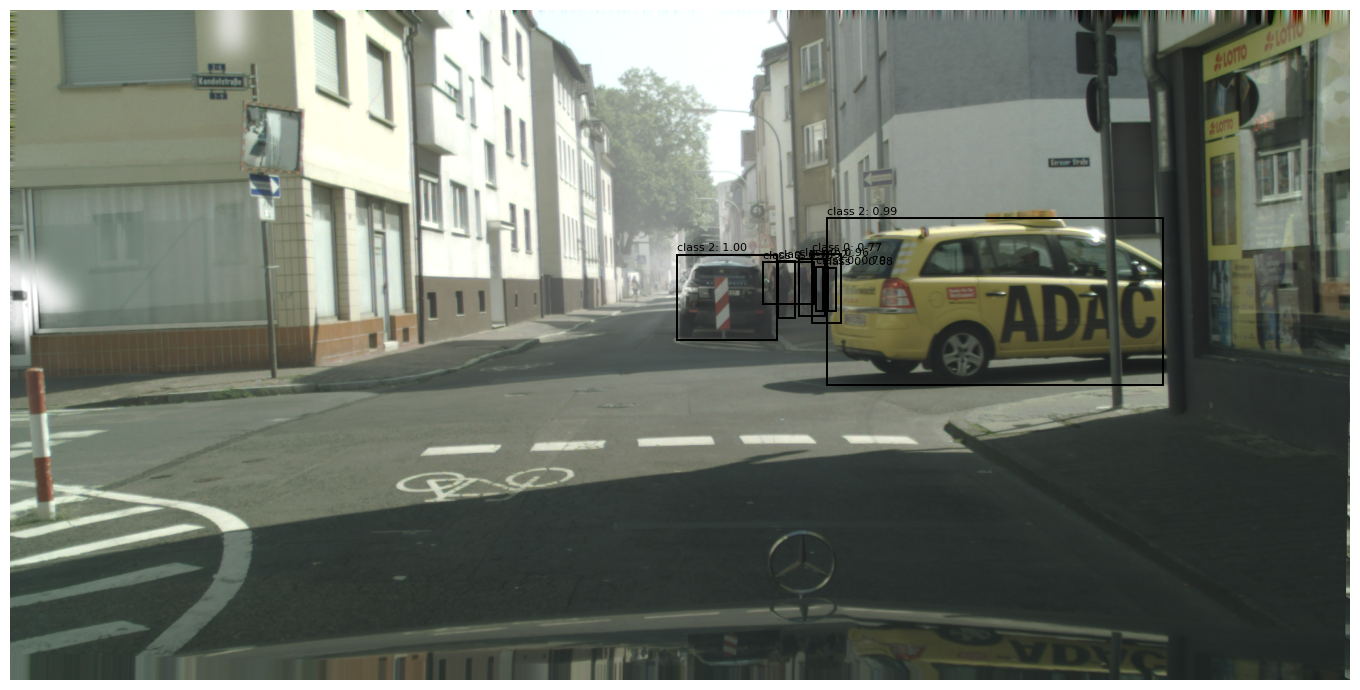

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
if SMOKE_IMAGE is not None and 'smoke_preds' in globals():
    im=np.asarray(Image.open(SMOKE_IMAGE).convert('RGB'))
    fig,ax=plt.subplots(figsize=(14,7))
    ax.imshow(im)
    for det in smoke_preds:
        if det['score']<0.60:continue
        x1,y1,x2,y2=det['bbox_xyxy']
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,linewidth=1.4))
        ax.text(x1,max(0,y1-5),f"class {det['class_id']}: {det['score']:.2f}",fontsize=8)
    ax.set_axis_off();plt.tight_layout()
    fig.savefig(OUT/'smoke_detections.png',dpi=160,bbox_inches='tight')
    plt.show()

## 8. Batch inference: 500 matched scenes × 3 fog levels

This section saves raw predictions with a **0.05 score floor**, not three separate inference runs. It resumes completed images and writes one JSON file per image, avoiding loss of progress. **Confirm the smoke test and manifest before enabling**. Runtime estimate is based on the measured one-image CPU time and may vary with image size and detection density.

In [8]:
RUN_BATCH = False  # Safety default: enable explicitly only when a new 1,500-image run is intended
if 'smoke_seconds' in globals():
    print('Approximate time for 1,500 images (hours):',round(smoke_seconds*1500/3600,2))
if RUN_BATCH:
    assert len(selected_scenes)==500
    assert 'smoke_preds' in globals(), 'Run and verify smoke test first.'
    records=[]
    for idx,sid in enumerate(selected_scenes,1):
        for fog in ('light','medium','strong'):
            image_path=images_by_fog[fog][sid]
            target=OUT/'predictions'/fog/f'{sid}.json'
            target.parent.mkdir(parents=True,exist_ok=True)
            if target.exists():
                data=json.loads(target.read_text())
            else:
                preds,secs,wh=infer_image(image_path)
                data={'scene_id':sid,'fog':fog,'image':str(image_path),'width':wh[0],'height':wh[1],
                      'elapsed_s':secs,'checkpoint_sha256':actual_hash,'predictions':preds}
                tmp=target.with_suffix('.tmp')
                tmp.write_text(json.dumps(data))
                tmp.replace(target)
            records.append({'scene_id':sid,'fog':fog,'seconds':data['elapsed_s'],'detections':len(data['predictions'])})
        if idx%10==0:print(f'{idx}/500 scenes completed')
    pd.DataFrame(records).to_csv(OUT/'inference_progress.csv',index=False)
    print('Batch complete:',len(records),'images')
else:
    print('Batch disabled. Set RUN_BATCH=True after validating smoke test and paths.')

Approximate time for 1,500 images (hours): 0.87
Batch disabled. Set RUN_BATCH=True after validating smoke test and paths.


In [9]:
import json

total = 0

for fog in ("light", "medium", "strong"):
    files = sorted((OUT / "predictions" / fog).glob("*.json"))
    detections = sum(
        len(json.loads(p.read_text())["predictions"])
        for p in files
    )

    print(f"{fog}: {len(files)} images, {detections} detections")
    total += len(files)

print(f"\nTotal images: {total}")
assert total == 1500, "Some prediction files are missing!"
print("SUCCESS: All 1,500 prediction files are present.")

light: 500 images, 42466 detections
medium: 500 images, 40661 detections
strong: 500 images, 36647 detections

Total images: 1500
SUCCESS: All 1,500 prediction files are present.


## 9. Ground-truth annotation mapping — mandatory before TP/FP claims

Predictions alone cannot establish true positives or false positives. Supply the **correct Cityscapes validation ground truth**, with bounding boxes, category mapping, crowd/ignore policy, and image IDs aligned to your selected scenes. For reproducibility this notebook accepts a user-verified COCO-format JSON. **Do not reuse category IDs blindly**: model class indices 0–7 must map to the dataset's eight categories. Ground truth is shared by the three fog renderings of each original scene.

Set `GT_COCO_JSON`, `MODEL_CLASS_TO_COCO_CAT`, and inspect the first matched annotations. The evaluation below uses greedy score-ordered matching at IoU≥0.50 and **is not official COCO mAP**. Crowd and ignored annotations are excluded; evaluate their treatment against your original experiment protocol.
**Annotation accounting:** The saved annotation-conversion manifest records 10,412 annotations per fog level, comprising 10,117 non-crowd objects and 295 crowd annotations. Across three matched fog versions, the COCO ground-truth file contains 31,236 annotation entries. Do not describe 10,117 as the total across all three fog levels.


In [10]:
# GT_COCO_JSON = None  # Path('/absolute/path/to/cityscapes_val_coco_instances.json')
# MODEL_CLASS_TO_COCO_CAT = None  # e.g. {0:..., 1:..., ... 7:...}; VERIFY category order from training metadata
GT_COCO_JSON = (
    ROOT / "Adaptive_teacher_Experiment 2/"
    "research_code_results/experiments/cityscapes_to_foggy/"
    "source_only/pretrained_smoke_v4/inference/"
    "cityscapes_foggy_val_coco_format.json"
)

MODEL_CLASS_TO_COCO_CAT = {
    0: 0,  # person
    1: 1,  # rider
    2: 2,  # car
    3: 3,  # truck
    4: 4,  # bus
    5: 5,  # train
    6: 6,  # motorcycle
    7: 7,  # bicycle
}
IOU_THRESHOLD=0.50
SCORE_THRESHOLDS=[0.80,0.70,0.60]

def bbox_iou_xyxy(a,b):
    ix1=max(a[0],b[0]);iy1=max(a[1],b[1]);ix2=min(a[2],b[2]);iy2=min(a[3],b[3])
    inter=max(0,ix2-ix1)*max(0,iy2-iy1)
    aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/(aa+bb-inter) if aa+bb-inter>0 else 0.

def coco_xywh_to_xyxy(b):return [b[0],b[1],b[0]+b[2],b[1]+b[3]]

def area_bucket(box):
    # COCO-style area ranges, using original-image pixel area.
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return 'small' if area<32**2 else ('medium' if area<96**2 else 'large')

if GT_COCO_JSON is not None:
    gt=json.loads(Path(GT_COCO_JSON).read_text())
    print('GT images:',len(gt['images']),'annotations:',len(gt['annotations']))
    print('Categories:',gt['categories'])
    assert MODEL_CLASS_TO_COCO_CAT is not None and set(MODEL_CLASS_TO_COCO_CAT)==set(range(8))
else:
    print('Ground truth not configured. TP/FP analysis will remain disabled.')

GT images: 1500 annotations: 31236
Categories: [{'id': 0, 'name': 'person'}, {'id': 1, 'name': 'rider'}, {'id': 2, 'name': 'car'}, {'id': 3, 'name': 'truck'}, {'id': 4, 'name': 'bus'}, {'id': 5, 'name': 'train'}, {'id': 6, 'name': 'motorcycle'}, {'id': 7, 'name': 'bicycle'}]


## 10. Evaluate per-scene TP, FP, FN by size

Matching is one-to-one within class and image, in descending confidence order. False detections are assigned a size bucket using the *predicted box*, while missed ground-truth objects use *ground-truth box* size. These size-specific FP counts are not equivalent to official COCO area-range evaluation. A model prediction that overlaps an ignored/crowd region may require special handling; this implementation **stops** if ignored annotations are present so they are not silently mislabeled FP.

In [12]:

import json
import numpy as np
import pandas as pd
from collections import defaultdict
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# ============================================================
# 1. Evaluation configuration
# ============================================================

BETAS = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

SCORE_THRESHOLDS = [0.80, 0.70, 0.60]
IOU_THRESHOLD = 0.50

assert len(selected_scenes) == 500
assert GT_COCO_JSON is not None
assert MODEL_CLASS_TO_COCO_CAT is not None
assert set(MODEL_CLASS_TO_COCO_CAT) == set(range(8))

print("Loading COCO ground truth...")

coco_gt = COCO(str(GT_COCO_JSON))

# Index exact filenames, not just scene IDs.
filename_to_image_id = {
    im["file_name"].split("/")[-1]: im["id"]
    for im in coco_gt.dataset["images"]
}

assert len(filename_to_image_id) == 1500

# ============================================================
# 2. Load saved predictions
# ============================================================

detections = []
image_ids_by_fog = defaultdict(list)

for fog, beta in BETAS.items():

    for sid in selected_scenes:

        filename = (
            f"{sid}_leftImg8bit_foggy_beta_{beta}.png"
        )

        assert filename in filename_to_image_id, (
            f"Missing ground truth: {filename}"
        )

        image_id = filename_to_image_id[filename]

        image_ids_by_fog[fog].append(image_id)

        prediction_file = (
            OUT / "predictions" / fog / f"{sid}.json"
        )

        assert prediction_file.exists(), (
            f"Missing predictions: {prediction_file}"
        )

        data = json.loads(prediction_file.read_text())

        assert data["scene_id"] == sid
        assert data["fog"] == fog
        assert data["checkpoint_sha256"] == actual_hash

        for pred in data["predictions"]:

            x1, y1, x2, y2 = pred["bbox_xyxy"]

            detections.append({
                "image_id": image_id,
                "category_id": MODEL_CLASS_TO_COCO_CAT[
                    int(pred["class_id"])
                ],
                "bbox": [
                    float(x1),
                    float(y1),
                    float(x2 - x1),
                    float(y2 - y1),
                ],
                "score": float(pred["score"]),
            })

print("Loaded predictions:", len(detections))

assert len(detections) == 119774

for fog in BETAS:
    assert len(image_ids_by_fog[fog]) == 500
    assert len(set(image_ids_by_fog[fog])) == 500

# ============================================================
# 3. COCO evaluation with crowd handling
# ============================================================

print("Preparing COCO evaluator...")

coco_dt = coco_gt.loadRes(detections)

evaluator = COCOeval(
    coco_gt,
    coco_dt,
    iouType="bbox"
)

evaluator.params.imgIds = sorted(
    image_id
    for ids in image_ids_by_fog.values()
    for image_id in ids
)

evaluator.params.catIds = sorted(
    set(MODEL_CLASS_TO_COCO_CAT.values())
)

evaluator.params.iouThrs = np.array([IOU_THRESHOLD])

# Preserve all saved predictions (typically fewer than 1000/image).
evaluator.params.maxDets = [1, 10, 1000]

print("Running COCO matching...")
evaluator.evaluate()

# ============================================================
# 4. Extract TP, FP, FN at each confidence threshold
# ============================================================

area_names = {
    0: "all",
    1: "small",
    2: "medium",
    3: "large",
}

rows = []

for ev in evaluator.evalImgs:

    if ev is None:
        continue

    image_id = ev["image_id"]
    category_id = int(ev["category_id"])

    # Determine area bucket using the evaluator's area range.
    area_range = tuple(float(x) for x in ev["aRng"])

    area_index = next(
        (
            i for i, rng in enumerate(evaluator.params.areaRng)
            if np.allclose(rng, area_range)
        ),
        None
    )

    if area_index is None:
        continue

    size = area_names[area_index]

    # COCO image IDs in this dataset are filenames.
    filename = str(image_id)
    sid = scene_id(filename)

    fog = next(
        fog_name
        for fog_name, beta in BETAS.items()
        if filename.endswith(f"_beta_{beta}.png")
    )

    dt_scores = np.asarray(
        ev["dtScores"], dtype=float
    )

    dt_ids = np.asarray(ev["dtIds"])

    dt_matches = np.asarray(
        ev["dtMatches"]
    )[0]

    dt_ignore = np.asarray(
        ev["dtIgnore"], dtype=bool
    )[0]

    gt_matches = np.asarray(
        ev["gtMatches"]
    )[0]

    gt_ignore = np.asarray(
        ev["gtIgnore"], dtype=bool
    )

    for threshold in SCORE_THRESHOLDS:

        selected = dt_scores >= threshold

        # True positives: matched and not ignored
        tp = int(np.sum(
            selected &
            (dt_matches > 0) &
            (~dt_ignore)
        ))

        # False positives: unmatched and not ignored
        fp = int(np.sum(
            selected &
            (dt_matches == 0) &
            (~dt_ignore)
        ))

        # COCO gtMatches contains matched detection IDs.
        # Only detections retained at this threshold count.
        selected_dt_ids = dt_ids[selected]

        fn = int(np.sum(
            (~gt_ignore) &
            (~np.isin(gt_matches, selected_dt_ids))
        ))

        for status, count in (
            ("TP", tp),
            ("FP", fp),
            ("FN", fn),
        ):
            rows.append({
                "scene_id": sid,
                "fog": fog,
                "threshold": threshold,
                "category_id": category_id,
                "status": status,
                "size": size,
                "count": count,
            })

# ============================================================
# 5. Save scene-level evaluation
# ============================================================

evaluation = pd.DataFrame(rows)

output_file = OUT / "scene_level_evaluation.csv"

evaluation.to_csv(output_file, index=False)

print("\nEvaluation rows:", len(evaluation))
print("Saved:", output_file)

# ============================================================
# 6. Aggregate threshold comparison
# ============================================================

# Use 'all' to avoid double-counting size buckets.
overall = evaluation[
    evaluation["size"] == "all"
]

summary = (
    overall
    .groupby(["fog", "threshold", "status"])["count"]
    .sum()
    .unstack("status", fill_value=0)
    .reset_index()
)

summary["precision"] = (
    summary["TP"] /
    (summary["TP"] + summary["FP"]).replace(0, np.nan)
)

summary["recall"] = (
    summary["TP"] /
    (summary["TP"] + summary["FN"]).replace(0, np.nan)
)

summary["f1"] = (
    2 * summary["precision"] * summary["recall"] /
    (summary["precision"] + summary["recall"])
)

summary = summary.sort_values(
    ["fog", "threshold"],
    ascending=[True, False]
)

summary_file = OUT / "threshold_comparison_final.csv"

summary.to_csv(summary_file, index=False)

print("\nFINAL THRESHOLD COMPARISON")
print(summary.to_string(index=False))

print("\nSaved:", summary_file)

# ============================================================
# 7. Sanity checks
# ============================================================

# assert len(evaluation) == (
#     1500 * 8 * 4 * 3 * 3
# ), "Unexpected number of evaluation rows"
print("Actual evaluation rows:", len(evaluation))

assert not evaluation.empty, "Evaluation is empty"

assert set(evaluation["fog"]) == set(BETAS.keys())

assert set(evaluation["threshold"]) == set(SCORE_THRESHOLDS)

assert set(evaluation["status"]) == {"TP", "FP", "FN"}

# Total non-ignored ground truth should be constant
# across confidence thresholds within each fog level.
summary["gt_total"] = summary["TP"] + summary["FN"]

for fog in BETAS:
    subset = summary[summary["fog"] == fog]
    assert subset["gt_total"].nunique() == 1, (
        f"Inconsistent GT count for {fog}"
    )

print("\nSUCCESS: Section 10 evaluation completed.")


Loading COCO ground truth...
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
Loaded predictions: 119774
Preparing COCO evaluator...
Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
Running COCO matching...
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.18s).

Evaluation rows: 267588
Saved: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/local_final_teacher_evaluation/scene_level_evaluation.csv

FINAL THRESHOLD COMPARISON
   fog  threshold   FN   FP   TP  precision   recall       f1
 light        0.8 6270 1464 3847   0.724346 0.380251 0.498704
 light        0.7 5899 2655 4218   0.613706 0.416922 0.496527
 light        0.6 5612 4267 4505   0.513566 0.445290 0.476997
medium        0.8 6390 1330 3727   0.736998 0.368390 0.491235
medium        0.7 6025 2444 4092   0.626071 0.404468 0.491443
medium        0.6 5763 3814 4354   0.533056 0.430365 0.476237


In [13]:
print("Actual evaluation rows:", len(evaluation))
print("Expected evaluation rows:", 1500 * 8 * 4 * 3 * 3)

print("\nRows by size:")
print(evaluation.groupby("size").size())

print("\nUnique scenes:", evaluation["scene_id"].nunique())
print("Fog levels:", evaluation["fog"].unique())
print("Thresholds:", evaluation["threshold"].unique())

print("\nThreshold comparison:")
print(summary.to_string(index=False))

Actual evaluation rows: 267588
Expected evaluation rows: 432000

Rows by size:
size
all       66897
large     66897
medium    66897
small     66897
dtype: int64

Unique scenes: 500
Fog levels: ['light' 'medium' 'strong']
Thresholds: [0.8 0.7 0.6]

Threshold comparison:
   fog  threshold   FN   FP   TP  precision   recall       f1  gt_total
 light        0.8 6270 1464 3847   0.724346 0.380251 0.498704     10117
 light        0.7 5899 2655 4218   0.613706 0.416922 0.496527     10117
 light        0.6 5612 4267 4505   0.513566 0.445290 0.476997     10117
medium        0.8 6390 1330 3727   0.736998 0.368390 0.491235     10117
medium        0.7 6025 2444 4092   0.626071 0.404468 0.491443     10117
medium        0.6 5763 3814 4354   0.533056 0.430365 0.476237     10117
strong        0.8 6677 1138 3440   0.751420 0.340022 0.468186     10117
strong        0.7 6384 2060 3733   0.644398 0.368983 0.469265     10117
strong        0.6 6127 3211 3990   0.554090 0.394386 0.460792     10117


In [14]:
overall = evaluation[evaluation["size"] == "all"]

summary_check = (
    overall.groupby(["fog", "threshold", "status"])["count"]
    .sum()
    .unstack("status", fill_value=0)
    .reset_index()
)

summary_check["GT_total"] = (
    summary_check["TP"] + summary_check["FN"]
)

print(summary_check.to_string(index=False))

print("\nGround-truth totals by fog:")
print(
    summary_check.groupby("fog")["GT_total"]
    .agg(["min", "max"])
)

   fog  threshold   FN   FP   TP  GT_total
 light        0.6 5612 4267 4505     10117
 light        0.7 5899 2655 4218     10117
 light        0.8 6270 1464 3847     10117
medium        0.6 5763 3814 4354     10117
medium        0.7 6025 2444 4092     10117
medium        0.8 6390 1330 3727     10117
strong        0.6 6127 3211 3990     10117
strong        0.7 6384 2060 3733     10117
strong        0.8 6677 1138 3440     10117

Ground-truth totals by fog:
          min    max
fog                 
light   10117  10117
medium  10117  10117
strong  10117  10117


In [15]:
size_summary = (
    evaluation[evaluation["size"] != "all"]
    .groupby(["fog", "threshold", "size", "status"])["count"]
    .sum()
    .unstack("status", fill_value=0)
    .reset_index()
)

size_summary["GT_total"] = (
    size_summary["TP"] + size_summary["FN"]
)

print(size_summary.to_string(index=False))

print("\nGT totals by fog and object size:")
print(
    size_summary.groupby(["fog", "size"])["GT_total"]
    .agg(["min", "max"])
)

   fog  threshold   size   FN   FP   TP  GT_total
 light        0.6  large  179 1063 1545      1724
 light        0.6 medium 1703 2558 2583      4286
 light        0.6  small 3668  652  442      4110
 light        0.7  large  214  730 1510      1724
 light        0.7 medium 1861 1606 2425      4286
 light        0.7  small 3762  325  348      4110
 light        0.8  large  253  472 1471      1724
 light        0.8 medium 2085  900 2201      4286
 light        0.8  small 3873  100  237      4110
medium        0.6  large  185 1056 1539      1724
medium        0.6 medium 1772 2307 2514      4286
medium        0.6  small 3749  457  361      4110
medium        0.7  large  217  728 1507      1724
medium        0.7 medium 1914 1518 2372      4286
medium        0.7  small 3839  205  271      4110
medium        0.8  large  259  459 1465      1724
medium        0.8 medium 2145  820 2141      4286
medium        0.8  small 3930   57  180      4110
strong        0.6  large  189 1047 1535      1724


In [16]:
import numpy as np
import pandas as pd

# Use overall results only, avoiding double-counting size ranges.
scene_counts = (
    evaluation[evaluation["size"] == "all"]
    .groupby(["scene_id", "fog", "threshold", "status"])["count"]
    .sum()
    .unstack("status", fill_value=0)
    .reset_index()
)

scene_ids = sorted(scene_counts["scene_id"].unique())
assert len(scene_ids) == 500

thresholds = [0.80, 0.70, 0.60]
fogs = ["light", "medium", "strong"]
statuses = ["TP", "FP", "FN"]

# Build aligned scene arrays: [scene, fog, threshold, status].
lookup = scene_counts.set_index(
    ["scene_id", "fog", "threshold"]
)

counts = np.zeros((500, 3, 3, 3), dtype=np.int64)

for i, sid in enumerate(scene_ids):
    for j, fog in enumerate(fogs):
        for k, threshold in enumerate(thresholds):
            row = lookup.loc[(sid, fog, threshold)]
            counts[i, j, k] = [
                int(row[s]) for s in statuses
            ]

# Paired scene-level bootstrap
rng = np.random.default_rng(42)
n_boot = 2000
bootstrap_indices = rng.integers(
    0, 500, size=(n_boot, 500)
)

boot_counts = counts[bootstrap_indices].sum(axis=1)

tp = boot_counts[..., 0]
fp = boot_counts[..., 1]
fn = boot_counts[..., 2]

precision = np.divide(
    tp, tp + fp,
    out=np.full(tp.shape, np.nan, dtype=float),
    where=(tp + fp) > 0
)

recall = np.divide(
    tp, tp + fn,
    out=np.full(tp.shape, np.nan, dtype=float),
    where=(tp + fn) > 0
)

f1 = np.divide(
    2 * tp,
    2 * tp + fp + fn,
    out=np.full(tp.shape, np.nan, dtype=float),
    where=(2 * tp + fp + fn) > 0
)

metric_arrays = {
    "precision": precision,
    "recall": recall,
    "f1": f1
}

results = []

for j, fog in enumerate(fogs):
    for k, threshold in enumerate(thresholds):
        for metric, values in metric_arrays.items():
            lo, hi = np.nanpercentile(
                values[:, j, k], [2.5, 97.5]
            )
            results.append({
                "fog": fog,
                "threshold": threshold,
                "metric": metric,
                "ci_lower": lo,
                "ci_upper": hi,
                "bootstrap_samples": n_boot
            })

bootstrap_ci = pd.DataFrame(results)

bootstrap_file = OUT / "bootstrap_95ci_final.csv"
bootstrap_ci.to_csv(bootstrap_file, index=False)

print(bootstrap_ci.to_string(index=False))
print("\nSaved:", bootstrap_file)

   fog  threshold    metric  ci_lower  ci_upper  bootstrap_samples
 light        0.8 precision  0.709908  0.739002               2000
 light        0.8    recall  0.365566  0.393206               2000
 light        0.8        f1  0.484456  0.511575               2000
 light        0.7 precision  0.598970  0.627502               2000
 light        0.7    recall  0.401737  0.430225               2000
 light        0.7        f1  0.483063  0.508729               2000
 light        0.6 precision  0.500326  0.526742               2000
 light        0.6    recall  0.430022  0.459295               2000
 light        0.6        f1  0.464271  0.489051               2000
medium        0.8 precision  0.722115  0.751588               2000
medium        0.8    recall  0.353691  0.381566               2000
medium        0.8        f1  0.476959  0.504154               2000
medium        0.7 precision  0.611500  0.639682               2000
medium        0.7    recall  0.390175  0.417989               

In [17]:
# Paired bootstrap: F1 difference between 0.70 and 0.80
# Uses the aligned 500-scene bootstrap arrays already created.

def compute_f1(tp, fp, fn):
    denominator = 2 * tp + fp + fn
    return np.divide(
        2 * tp,
        denominator,
        out=np.full(denominator.shape, np.nan, dtype=float),
        where=denominator > 0
    )

# Existing arrays:
# boot_counts: [bootstrap_sample, fog, threshold, status]
# fogs: ["light", "medium", "strong"]
# thresholds: [0.80, 0.70, 0.60]

f1_boot = compute_f1(
    boot_counts[..., 0],
    boot_counts[..., 1],
    boot_counts[..., 2]
)

results = []

for j, fog in enumerate(fogs):
    idx_80 = thresholds.index(0.80)
    idx_70 = thresholds.index(0.70)

    # Paired comparison using identical resampled scenes
    difference = (
        f1_boot[:, j, idx_70] -
        f1_boot[:, j, idx_80]
    )

    lower, upper = np.nanpercentile(
        difference, [2.5, 97.5]
    )

    results.append({
        "fog": fog,
        "comparison": "0.70 - 0.80",
        "mean_f1_difference_pp": round(
            float(np.nanmean(difference) * 100), 3
        ),
        "ci_lower_pp": round(float(lower * 100), 3),
        "ci_upper_pp": round(float(upper * 100), 3),
        "ci_excludes_zero": bool(lower > 0 or upper < 0)
    })

paired_results = pd.DataFrame(results)

print(paired_results.to_string(index=False))

paired_results.to_csv(
    OUT / "paired_threshold_comparison.csv",
    index=False
)

   fog  comparison  mean_f1_difference_pp  ci_lower_pp  ci_upper_pp  ci_excludes_zero
 light 0.70 - 0.80                 -0.216       -0.594        0.187             False
medium 0.70 - 0.80                  0.020       -0.419        0.477             False
strong 0.70 - 0.80                  0.111       -0.263        0.490             False


In [18]:
print("Model classes:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
print("Class mapping:", MODEL_CLASS_TO_COCO_CAT)
print("GT categories:", [
    (c["id"], c["name"])
    for c in gt["categories"]
])
print("Checkpoint SHA256:", actual_hash)

Model classes: 8
Class mapping: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7}
GT categories: [(0, 'person'), (1, 'rider'), (2, 'car'), (3, 'truck'), (4, 'bus'), (5, 'train'), (6, 'motorcycle'), (7, 'bicycle')]
Checkpoint SHA256: bc37e39a71c468bc40b77cadb66d7aba6c1e6042eecf7446c94d40e14da0e1bd


In [19]:
from collections import Counter

# Count non-crowd GT objects by COCO annotation area
areas = [
    float(a["area"])
    for a in gt["annotations"]
    if not a.get("iscrowd", 0)
    and not a.get("ignore", 0)
]

print("Non-crowd annotations across all fog levels:", len(areas))

print("Objects exactly at size boundaries:")
print("Area = 1024:", sum(a == 1024 for a in areas))
print("Area = 9216:", sum(a == 9216 for a in areas))

print("\nCOCO size buckets using half-open intervals:")
print("Small:", sum(a < 1024 for a in areas))
print("Medium:", sum(1024 <= a < 9216 for a in areas))
print("Large:", sum(a >= 9216 for a in areas))

Non-crowd annotations across all fog levels: 30351
Objects exactly at size boundaries:
Area = 1024: 9
Area = 9216: 0

COCO size buckets using half-open intervals:
Small: 12321
Medium: 12858
Large: 5172


In [20]:
from pathlib import Path

project_root = Path.cwd()
expected = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
]

print("Expected class order:", expected)

for path in project_root.rglob("*.py"):
    if any(x in path.parts for x in [".venv", "site-packages", ".git"]):
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    for i, line in enumerate(lines):
        if (
            "thing_classes" in line
            or "CITYSCAPES_THING_CLASSES" in line
        ):
            print(f"\nFile: {path}")
            print(f"Line {i + 1}: {line.strip()}")
            for extra in lines[i + 1:i + 5]:
                print(extra)

Expected class order: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']


In [21]:
from pathlib import Path

root = Path.cwd()

for path in root.rglob("*.py"):
    if ".venv" in path.parts or ".git" in path.parts:
        continue

    if path.name not in [
        "builtin_meta.py",
        "register_foggy_datasets.py",
        "cityscapes.py",
        "builtin.py",
    ]:
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    for i, line in enumerate(lines):
        if any(term in line for term in [
            "CITYSCAPES_THING_CLASSES",
            "CITYSCAPES_CATEGORIES",
            "source_meta =",
            "thing_classes =",
            '"thing_classes":',
        ]):
            print(f"\nFILE: {path}")
            print(f"LINE: {i + 1}")
            print("\n".join(lines[max(0, i-3):i+10]))

In [22]:
from detectron2.data import MetadataCatalog, DatasetCatalog

print("Registered Cityscapes datasets:")

for name in DatasetCatalog.list():
    if "cityscapes" in name.lower() or "foggy" in name.lower():
        metadata = MetadataCatalog.get(name)
        print("\nDataset:", name)
        print("Classes:", metadata.get("thing_classes", None))

Registered Cityscapes datasets:

Dataset: cityscapes_fine_instance_seg_train
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_sem_seg_train
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_instance_seg_val
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_sem_seg_val
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_instance_seg_test
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_sem_seg_test
Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Dataset: cityscapes_fine_panoptic_train
Classes: ['road', 'sidewalk', 'building', 'wall', 'fence', 'pole', 'traffic light', 'traffic sign', 'vegetation', 'terrain', 'sky', 'person', 'rider', 'car', 'tru

In [23]:
import numpy as np
import pandas as pd
from pycocotools.cocoeval import COCOeval

fog_to_ids = {
    fog: sorted(
        img["id"]
        for img in gt["images"]
        if fog in img["file_name"]
    )
    for fog in ["light", "medium", "strong"]
}

# Prefer the known beta values rather than fog labels in filenames.
fog_to_ids = {"light": [], "medium": [], "strong": []}

for img in gt["images"]:
    filename = img["file_name"]
    if "beta_0.005" in filename:
        fog_to_ids["light"].append(img["id"])
    elif "beta_0.01" in filename:
        fog_to_ids["medium"].append(img["id"])
    elif "beta_0.02" in filename:
        fog_to_ids["strong"].append(img["id"])

print("Images per fog:", {
    k: len(v) for k, v in fog_to_ids.items()
})

assert all(len(v) == 500 for v in fog_to_ids.values())

results = []

for fog, image_ids in fog_to_ids.items():
    ev = COCOeval(coco_gt, coco_dt, "bbox")
    ev.params.imgIds = image_ids
    ev.params.catIds = list(range(8))
    ev.params.iouThrs = np.array([0.50])
    ev.params.maxDets = [1, 10, 100]

    ev.evaluate()
    ev.accumulate()

    # Precision shape:
    # [IoU, recall, category, area, maxDet]
    precision = ev.eval["precision"][0, :, :, 0, 2]
    valid = precision[precision >= 0]

    ap50 = float(np.mean(valid)) if valid.size else np.nan

    results.append({
        "fog": fog,
        "images": len(image_ids),
        "AP50": ap50,
        "AP50_percent": ap50 * 100
    })

ap50_results = pd.DataFrame(results)

print("\nAP50 results:")
print(ap50_results.to_string(index=False))

ap50_results.to_csv(
    OUT / "ap50_by_fog_final.csv",
    index=False
)

Images per fog: {'light': 500, 'medium': 500, 'strong': 500}
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.55s).
Accumulating evaluation results...
DONE (t=0.07s).
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.39s).
Accumulating evaluation results...
DONE (t=0.06s).
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.37s).
Accumulating evaluation results...
DONE (t=0.06s).

AP50 results:
   fog  images     AP50  AP50_percent
 light     500 0.329891     32.989139
medium     500 0.312201     31.220147
strong     500 0.283447     28.344674


In [24]:
class_ap_results = []

for fog, image_ids in fog_to_ids.items():
    ev = COCOeval(coco_gt, coco_dt, "bbox")
    ev.params.imgIds = image_ids
    ev.params.catIds = list(range(8))
    ev.params.iouThrs = np.array([0.50])
    ev.params.maxDets = [1, 10, 100]

    ev.evaluate()
    ev.accumulate()

    precision = ev.eval["precision"]

    for k, category_id in enumerate(ev.params.catIds):
        p = precision[0, :, k, 0, 2]
        valid = p[p >= 0]

        ap = float(valid.mean()) if valid.size else np.nan

        class_ap_results.append({
            "fog": fog,
            "class": coco_gt.cats[category_id]["name"],
            "AP50_percent": ap * 100
        })

class_ap_df = pd.DataFrame(class_ap_results)

class_ap_table = class_ap_df.pivot(
    index="class",
    columns="fog",
    values="AP50_percent"
).reindex(columns=["light", "medium", "strong"])

class_ap_table["drop_light_to_strong_pp"] = (
    class_ap_table["light"] - class_ap_table["strong"]
)

print(class_ap_table.round(2).to_string())

class_ap_table.to_csv(
    OUT / "classwise_ap50_final.csv"
)

Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.41s).
Accumulating evaluation results...
DONE (t=0.06s).
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.41s).
Accumulating evaluation results...
DONE (t=0.06s).
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.36s).
Accumulating evaluation results...
DONE (t=0.06s).
fog         light  medium  strong  drop_light_to_strong_pp
class                                                     
bicycle     35.62   35.97   34.60                     1.02
bus         32.58   27.62   23.36                     9.22
car         55.89   54.10   50.14                     5.75
motorcycle  27.49   27.80   25.57                     1.92
person      30.55   30.48   28.62                     1.93
rider       42.30   41.19   39.71                     2.59
train       15.17   12.89    5.54                     9.63
truck       24.31   19.71   19.22                     5.09


In [25]:
from collections import Counter
import pandas as pd

rows = []

for fog, image_ids in fog_to_ids.items():
    image_id_set = set(image_ids)

    annotations = [
        ann for ann in gt["annotations"]
        if ann["image_id"] in image_id_set
        and not ann.get("iscrowd", 0)
        and not ann.get("ignore", 0)
    ]

    counts = Counter(
        ann["category_id"] for ann in annotations
    )

    for category_id in range(8):
        rows.append({
            "fog": fog,
            "class": coco_gt.cats[category_id]["name"],
            "gt_objects": counts[category_id]
        })

class_counts = pd.DataFrame(rows)

print(
    class_counts.pivot(
        index="class",
        columns="fog",
        values="gt_objects"
    ).to_string()
)

print("\nTotal GT objects per fog:")
print(class_counts.groupby("fog")["gt_objects"].sum())

fog         light  medium  strong
class                            
bicycle      1165    1165    1165
bus            98      98      98
car          4652    4652    4652
motorcycle    149     149     149
person       3394    3394    3394
rider         543     543     543
train          23      23      23
truck          93      93      93

Total GT objects per fog:
fog
light     10117
medium    10117
strong    10117
Name: gt_objects, dtype: int64


In [26]:
import pandas as pd

# Summarize true and false positives by fog, size and threshold.
size_counts = (
    evaluation[evaluation["size"].isin(
        ["small", "medium", "large"]
    )]
    .groupby(["fog", "size", "threshold", "status"])["count"]
    .sum()
    .unstack("status", fill_value=0)
    .reset_index()
)

rows = []

for fog in ["light", "medium", "strong"]:
    for size in ["small", "medium", "large"]:
        subset = size_counts[
            (size_counts["fog"] == fog) &
            (size_counts["size"] == size)
        ].set_index("threshold")

        for high, low in [(0.80, 0.70), (0.70, 0.60)]:
            rows.append({
                "fog": fog,
                "size": size,
                "threshold_change": f"{high:.2f} -> {low:.2f}",
                "additional_TP": int(
                    subset.loc[low, "TP"] -
                    subset.loc[high, "TP"]
                ),
                "additional_FP": int(
                    subset.loc[low, "FP"] -
                    subset.loc[high, "FP"]
                ),
                "additional_FN_recovered": int(
                    subset.loc[high, "FN"] -
                    subset.loc[low, "FN"]
                )
            })

incremental_size = pd.DataFrame(rows)

print(incremental_size.to_string(index=False))

incremental_size.to_csv(
    OUT / "incremental_recovery_by_size.csv",
    index=False
)

   fog   size threshold_change  additional_TP  additional_FP  additional_FN_recovered
 light  small     0.80 -> 0.70            111            225                      111
 light  small     0.70 -> 0.60             94            327                       94
 light medium     0.80 -> 0.70            224            706                      224
 light medium     0.70 -> 0.60            158            952                      158
 light  large     0.80 -> 0.70             39            258                       39
 light  large     0.70 -> 0.60             35            333                       35
medium  small     0.80 -> 0.70             91            148                       91
medium  small     0.70 -> 0.60             90            252                       90
medium medium     0.80 -> 0.70            231            698                      231
medium medium     0.70 -> 0.60            142            789                      142
medium  large     0.80 -> 0.70             42         

In [27]:
import numpy as np
import pandas as pd

# Build scene-level TP/FP counts by fog, size and threshold.
scene_size = (
    evaluation[evaluation["size"].isin(["small", "medium", "large"])]
    .groupby(
        ["scene_id", "fog", "size", "threshold", "status"]
    )["count"]
    .sum()
    .unstack("status", fill_value=0)
)

scene_ids = sorted(evaluation["scene_id"].unique())
fogs = ["light", "medium", "strong"]
sizes = ["small", "medium", "large"]
thresholds = [0.80, 0.70, 0.60]

# Shape: scenes × fog × size × threshold × [TP, FP]
counts = np.zeros((500, 3, 3, 3, 2), dtype=np.int64)

for i, sid in enumerate(scene_ids):
    for j, fog in enumerate(fogs):
        for k, size in enumerate(sizes):
            for m, threshold in enumerate(thresholds):
                key = (sid, fog, size, threshold)
                if key in scene_size.index:
                    row = scene_size.loc[key]
                    counts[i, j, k, m] = [
                        int(row.get("TP", 0)),
                        int(row.get("FP", 0))
                    ]

# Resample the same scenes for all conditions.
rng = np.random.default_rng(42)
n_boot = 2000
indices = rng.integers(
    0, len(scene_ids),
    size=(n_boot, len(scene_ids))
)

# Sum TP and FP across resampled scenes.
boot = counts[indices].sum(axis=1)

results = []

for j, fog in enumerate(fogs):
    for k, size in enumerate(sizes):
        for high, low in [(0.80, 0.70), (0.70, 0.60)]:
            hi = thresholds.index(high)
            lo = thresholds.index(low)

            differences = boot[:, j, k, lo] - boot[:, j, k, hi]
            observed = counts[:, j, k, lo].sum(axis=0) - (
                counts[:, j, k, hi].sum(axis=0)
            )

            tp_ci = np.percentile(differences[:, 0], [2.5, 97.5])
            fp_ci = np.percentile(differences[:, 1], [2.5, 97.5])

            results.append({
                "fog": fog,
                "size": size,
                "change": f"{high:.2f} -> {low:.2f}",
                "additional_TP": int(observed[0]),
                "TP_CI_lower": round(float(tp_ci[0]), 1),
                "TP_CI_upper": round(float(tp_ci[1]), 1),
                "additional_FP": int(observed[1]),
                "FP_CI_lower": round(float(fp_ci[0]), 1),
                "FP_CI_upper": round(float(fp_ci[1]), 1)
            })

incremental_bootstrap = pd.DataFrame(results)

print(incremental_bootstrap.to_string(index=False))

incremental_bootstrap.to_csv(
    OUT / "incremental_recovery_bootstrap_95ci.csv",
    index=False
)

   fog   size       change  additional_TP  TP_CI_lower  TP_CI_upper  additional_FP  FP_CI_lower  FP_CI_upper
 light  small 0.80 -> 0.70            111         90.0        134.0            225        188.0        267.0
 light  small 0.70 -> 0.60             94         74.0        115.0            327        284.0        371.0
 light medium 0.80 -> 0.70            224        195.0        255.0            706        632.0        788.0
 light medium 0.70 -> 0.60            158        130.0        185.0            952        869.0       1038.0
 light  large 0.80 -> 0.70             39         26.0         52.0            258        219.0        298.0
 light  large 0.70 -> 0.60             35         23.0         48.0            333        287.0        381.0
medium  small 0.80 -> 0.70             91         70.0        116.0            148        117.0        183.0
medium  small 0.70 -> 0.60             90         70.0        112.0            252        214.0        293.0
medium medium 0.80 

## 13. Reproducibility metadata and export

The metadata records model identity, exact local config, environment versions, inference score floor, dataset roots, selected scene IDs, matching protocol, and output paths. Review the configuration and ground-truth mapping before using tables in a paper.

In [28]:
import yaml
metadata={
 'checkpoint_path':str(CHECKPOINT),'checkpoint_sha256':actual_hash,'checkpoint_iteration':4999,
 'teacher_branch':'modelTeacher','teacher_tensors':113,'config_path':str(CONFIG),
 'config_sha256':sha256_file(CONFIG),'architecture':cfg.MODEL.META_ARCHITECTURE,
 'backbone':cfg.MODEL.BACKBONE.NAME,'device':'cpu','inference_score_floor':float(cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST),
 'training_pseudo_label_threshold':float(cfg.SEMISUPNET.BBOX_THRESHOLD),
 'thresholds':SCORE_THRESHOLDS,'iou_threshold':IOU_THRESHOLD,
 'image_roots':{k:str(v) if v is not None else None for k,v in IMAGE_ROOTS.items()},
 'selected_scene_count':len(selected_scenes),'scene_ids':selected_scenes,
 'ground_truth_path':str(GT_COCO_JSON) if GT_COCO_JSON else None,
 'model_class_to_coco_category':MODEL_CLASS_TO_COCO_CAT,
 'python':sys.version,'torch':torch.__version__,'platform':platform.platform(),
 'notes':['Verified model loading; actual inference must pass smoke test.',
          'Greedy IoU@0.5 matching is not official COCO mAP.',
          'Ground-truth ignore/crowd behavior must be validated before evaluation.',
          'Predictions are from one final 0.80-trained teacher, filtered post hoc by score.']
}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2,default=str))
print('Saved metadata:',OUT/'run_metadata.json')
print('Saved results directory:',OUT)

Saved metadata: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/local_final_teacher_evaluation/run_metadata.json
Saved results directory: /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/local_final_teacher_evaluation


## Reproducibility and handoff notes

- Final teacher checkpoint: iteration 4,999; verify SHA256 using the checkpoint cell.
- Evaluation uses 500 paired scenes at each of three fog densities (1,500 images).
- Detection-score thresholds (0.80, 0.70, 0.60) are **post-hoc inference thresholds**, distinct from the training pseudo-label threshold (0.80).
- The annotation conversion manifest reports **10,412 ground-truth annotations per fog level = 10,117 non-crowd + 295 crowd**. The combined three-fog COCO file reports 31,236 annotation entries.
- Check the class mapping, image alignment, crowd/ignore handling, and matching protocol before publishing TP/FP or AP claims.
- Some exploratory inspection cells remain to document checks performed during the run.
- The historical output cells have been retained as evidence; they were **not re-executed** during notebook cleaning.
- The batch-inference flag defaults to `False` to avoid unintentionally repeating a costly run.
- Use the exported CSVs and the corrected figure notebook for the final report; do not substitute the superseded legacy threshold/bootstrap cells.


In [4]:
from pathlib import Path
import yaml

ROOT = Path.home() / "Desktop/phd/vizuara/Deliverables/milestone2"
EXP = ROOT / "Adaptive_teacher_Experiment 2"

config_path = (
    EXP / "research_code_results/experiments/cityscapes_to_foggy/"
    "adaptive_teacher/pilot_5000_v1/config.yaml"
)

with open(config_path) as f:
    config = yaml.safe_load(f)

print("=== TRAINING CONFIGURATION ===")
print("DATASETS:", config.get("DATASETS", {}))
print("SOLVER:", config.get("SOLVER", {}))
print("SEMISUPNET:", config.get("SEMISUPNET", {}))

print("\n=== DATASET REGISTRATION ===")

registration_files = [
    ROOT / "research_code/adaptive_teacher/adapteacher/data/datasets/builtin.py",
    EXP / "research_code_results/adaptive_teacher_recovered/adaptive_teacher/adapteacher/data/datasets/builtin.py",
]

for path in registration_files:
    if not path.exists():
        continue

    print(f"\nFile: {path}")

    lines = path.read_text(errors="ignore").splitlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "cityscapes", "foggy", "register_coco", "datasetcatalog.register"
        ]):
            print(f"{i+1}: {line.strip()[:180]}")

=== TRAINING CONFIGURATION ===
DATASETS: {'CROSS_DATASET': True, 'PRECOMPUTED_PROPOSAL_TOPK_TEST': 1000, 'PRECOMPUTED_PROPOSAL_TOPK_TRAIN': 2000, 'PROPOSAL_FILES_TEST': [], 'PROPOSAL_FILES_TRAIN': [], 'TEST': ['cityscapes_foggy_val'], 'TRAIN': ['cityscapes_fine_instance_seg_train'], 'TRAIN_LABEL': ['cityscapes_fine_instance_seg_train'], 'TRAIN_UNLABEL': ['cityscapes_foggy_train']}
SOLVER: {'AMP': {'ENABLED': False}, 'BASE_LR': 0.0005, 'BASE_LR_END': 0.0, 'BIAS_LR_FACTOR': 1.0, 'CHECKPOINT_PERIOD': 1000, 'CLIP_GRADIENTS': {'CLIP_TYPE': 'value', 'CLIP_VALUE': 1.0, 'ENABLED': False, 'NORM_TYPE': 2.0}, 'FACTOR_LIST': [1.0], 'GAMMA': 0.1, 'IMG_PER_BATCH_LABEL': 2, 'IMG_PER_BATCH_UNLABEL': 2, 'IMS_PER_BATCH': 2, 'LR_SCHEDULER_NAME': 'WarmupTwoStageMultiStepLR', 'MAX_ITER': 5000, 'MOMENTUM': 0.9, 'NESTEROV': False, 'NUM_DECAYS': 3, 'REFERENCE_WORLD_SIZE': 0, 'RESCALE_INTERVAL': False, 'STEPS': [], 'WARMUP_FACTOR': 0.001, 'WARMUP_ITERS': 100, 'WARMUP_METHOD': 'linear', 'WEIGHT_DECAY': 0.0001, 

In [6]:
import sys
from pathlib import Path

ROOT = Path.home() / "Desktop/phd/vizuara/Deliverables/milestone2"
REPO = ROOT / "Adaptive_teacher_Experiment 2/research_code_results/adaptive_teacher_recovered/adaptive_teacher"

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# Importing the module executes its registration definitions.
import adapteacher.data.datasets.builtin

from detectron2.data import DatasetCatalog

print("=== DATASET REGISTRATION AFTER IMPORT ===")

for name in [
    "cityscapes_fine_instance_seg_train",
    "cityscapes_foggy_train",
    "cityscapes_foggy_val"
]:
    print(name, ":", name in DatasetCatalog.list())

=== DATASET REGISTRATION AFTER IMPORT ===
cityscapes_fine_instance_seg_train : True
cityscapes_foggy_train : True
cityscapes_foggy_val : True


In [15]:
from pathlib import Path
import sys
import importlib.util

ROOT = Path.home() / "Desktop/phd/vizuara/Deliverables/milestone2"

COMPAT = (
    ROOT
    / "Adaptive_teacher_Experiment 2"
    / "research_code_results/experiments/cityscapes_to_foggy"
    / "source_only/pilot_1000_v1/python_compat"
)

CITYSCAPES_API = (
    COMPAT
    / "deeplearning/projects/cityscapesApi"
)

for path in [COMPAT, CITYSCAPES_API]:
    assert path.is_dir(), f"Missing directory: {path}"
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

print("=== MODULE VERIFICATION ===")

for module in ["deeplearning", "cityscapesscripts"]:
    spec = importlib.util.find_spec(module)
    print(module, ":", spec.origin if spec else "NOT FOUND")

=== MODULE VERIFICATION ===
deeplearning : /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/research_code_results/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/python_compat/deeplearning/__init__.py
cityscapesscripts : /Users/mohammadmeraj/Desktop/phd/vizuara/Deliverables/milestone2/Adaptive_teacher_Experiment 2/research_code_results/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/python_compat/deeplearning/projects/cityscapesApi/cityscapesscripts/__init__.py


In [18]:
%pip install cityscapesscripts

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for typing: filename=typing-3.7.4.3-py3-none-any.whl size=26399 sha256=d5aa42ac79489d53e0e97dfe5360aa8d8d491f6fdb21686b1fdb05966381189e
  Stored in directory: /Users/mohammadmeraj/Library/Caches/pip/wheels/7c/d0/9e/1f26ebb66d9e1732e4098bc5a6c2d91f6c9a529838f0284890
Successfully built typing
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [cityscapesscripts]
Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install shapely

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 1.5 MB/s  0:00:01 eta 0:00:010m
Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import os
from detectron2.data import DatasetCatalog

ROOT = Path.home() / "Desktop/phd/vizuara/Deliverables/milestone2"
DATASET_BASE = ROOT / "external/adaptive_teacher"

original_dir = Path.cwd()

try:
    os.chdir(DATASET_BASE)

    for name in [
        "cityscapes_fine_instance_seg_train",
        "cityscapes_foggy_train",
        "cityscapes_foggy_val",
    ]:
        print(f"\n=== {name} ===")

        try:
            records = DatasetCatalog.get(name)

            print("Images loaded:", len(records))
            print(
                "First image exists:",
                bool(records) and Path(records[0]["file_name"]).exists()
            )

        except Exception as e:
            print("FAILED:", type(e).__name__, str(e)[:300])

finally:
    os.chdir(original_dir)


=== cityscapes_fine_instance_seg_train ===
Images loaded: 2975
First image exists: True

=== cityscapes_foggy_train ===
Images loaded: 8925
First image exists: True

=== cityscapes_foggy_val ===
Images loaded: 1500
First image exists: True



### Dataset Registration and Loading Verification

The dataset registration and loading checks were successfully completed using the recovered Adaptive Teacher configuration.

| Registered dataset | Images loaded | Image path verified |
|---|---:|---|
| `cityscapes_fine_instance_seg_train` | 2,975 | Yes |
| `cityscapes_foggy_train` | 8,925 | Yes |
| `cityscapes_foggy_val` | 1,500 | Yes |

The Foggy Cityscapes training and validation sets contain three fog-severity variants per original image.

The local checks confirm that the registered datasets can be loaded and their image paths resolve correctly.

**Limitation:** These checks establish current local dataset-loading correctness, but do not independently verify the dataset usage of the historical training run.


In [11]:
from pathlib import Path
import hashlib
import re
import pandas as pd
from IPython.display import display

# ============================================================
# HISTORICAL TRAINING VERIFICATION
# Portable evidence | SHA-256 integrity | Read-only
# ============================================================

EVIDENCE = Path("training_verification_evidence")

# Support execution from either the notebook folder
# or the milestone2 project root.
if not EVIDENCE.is_dir():
    EVIDENCE = (
        Path("Adaptive_teacher_Experiment")
        / "training_verification_evidence"
    )

if not EVIDENCE.is_dir():
    raise FileNotFoundError(
        "Evidence folder not found. Run this notebook from "
        "Adaptive_teacher_Experiment or milestone2."
    )

expected_hashes = {
    "pilot_5000_v1_log.txt":
        "1dd6f8f969282ef20f0601cc45af5cc7da8421fb0e3d040f81c5f9ce81dae561",
    "pilot_5000_warmstart_v2_log.txt":
        "8aacb163e3ef5b0865cb7e1371ef1cd84a8d5c3abeb8814bc601a6e5ed23f9c9",
}

# Verify file integrity before reading evidence
logs = {}

for filename, expected_hash in expected_hashes.items():
    path = EVIDENCE / filename

    if not path.is_file():
        raise FileNotFoundError(path)

    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()

    if actual_hash != expected_hash:
        raise ValueError(
            f"SHA-256 mismatch for {filename}: {actual_hash}"
        )

    logs[filename] = path.read_text(
        encoding="utf-8",
        errors="replace"
    )

print("SHA-256 INTEGRITY: 2/2 PASS")

# Remove ANSI terminal color codes
ansi = re.compile(r"\x1b\[[0-?]*[ -/]*[@-~]")

original_log = ansi.sub("", logs["pilot_5000_v1_log.txt"])
warmstart_log = ansi.sub(
    "",
    logs["pilot_5000_warmstart_v2_log.txt"]
)

# Historical verification checks
checks = [
    (
        "Cross-dataset training enabled",
        bool(re.search(
            r"CROSS_DATASET:\s*true",
            original_log,
            re.I
        ))
    ),
    (
        "Labeled Cityscapes configured",
        bool(re.search(
            r"TRAIN_LABEL:\s*-\s*cityscapes_fine_instance_seg_train",
            original_log
        ))
    ),
    (
        "Unlabeled Foggy Cityscapes configured",
        bool(re.search(
            r"TRAIN_UNLABEL:\s*-\s*cityscapes_foggy_train",
            original_log
        ))
    ),
    (
        "Foggy Cityscapes validation configured",
        bool(re.search(
            r"TEST:\s*-\s*cityscapes_foggy_val",
            original_log
        ))
    ),
    (
        "Historical source images loaded",
        "Loaded 2975 images" in original_log
    ),
    (
        "Source annotation filtering recorded",
        "2965 images left" in original_log
    ),
    (
        "Original pilot reached iteration 153",
        bool(re.search(r"\biter:\s*153\b", original_log))
    ),
    (
        "Warm-start reached iteration 4999",
        bool(re.search(r"\biter:\s*4999\b", warmstart_log))
    ),
    (
        "Target-domain discriminator loss logged",
        "loss_D_img_t:" in warmstart_log
    ),
    (
        "Pseudo-label classification loss logged",
        "loss_cls_pseudo:" in warmstart_log
    ),
    (
        "Pseudo-label box regression loss logged",
        "loss_box_reg_pseudo:" in warmstart_log
    ),
    (
        "Pseudo-label RPN losses logged",
        all(
            name in warmstart_log
            for name in (
                "loss_rpn_cls_pseudo:",
                "loss_rpn_loc_pseudo:"
            )
        )
    )
]

results = pd.DataFrame([
    {
        "Verification": name,
        "Result": "PASS" if passed else "NOT VERIFIED"
    }
    for name, passed in checks
])

print("\nHISTORICAL TRAINING VERIFICATION")
print("=" * 65)

display(results)

passed = sum(ok for _, ok in checks)

print(f"\nVerification checks passed: {passed}/{len(checks)}")

# Extract historical training progress
def highest_iteration(text):
    values = re.findall(r"\biter:\s*(\d+)\b", text)
    return max(map(int, values)) if values else None

print("\nTRAINING PROGRESS")
print("-" * 65)

print("Original pilot:", highest_iteration(original_log))
print("Warm-start:", highest_iteration(warmstart_log))

# Preserve concise evidence excerpts
print("\nHISTORICAL LOG EXCERPTS")
print("-" * 65)

patterns = [
    ("Source loading", original_log, r"^.*Loaded 2975 images.*$"),
    ("Source filtering", original_log, r"^.*2965 images left.*$"),
    ("Final iteration", warmstart_log, r"^.*iter:\s*4999\b.*$"),
    (
        "Training duration",
        warmstart_log,
        r"^.*Overall training speed: 4997 iterations.*$"
    ),
]

for label, text, pattern in patterns:
    matches = re.findall(pattern, text, flags=re.MULTILINE)
    print(f"\n{label}:")
    print(matches[-1].strip() if matches else "NOT FOUND")

print("\nFINAL ASSESSMENT")
print("-" * 65)

if passed == len(checks):
    print("PASS: All 12 historical verification checks passed.")
else:
    print("PARTIAL: Some historical checks require investigation.")

print(
    "\nLimitation: Exact historical target-image counts and "
    "sample identities are not independently established."
)

SHA-256 INTEGRITY: 2/2 PASS

HISTORICAL TRAINING VERIFICATION


,Verification,Result
0,Cross-dataset training enabled,PASS
1,Labeled Cityscapes configured,PASS
2,Unlabeled Foggy Cityscapes configured,PASS
3,Foggy Cityscapes validation configured,PASS
4,Historical source images loaded,PASS
5,Source annotation filtering recorded,PASS
6,Original pilot reached iteration 153,PASS
7,Warm-start reached iteration 4999,PASS
8,Target-domain discriminator loss logged,PASS
9,Pseudo-label classification loss logged,PASS



Verification checks passed: 12/12

TRAINING PROGRESS
-----------------------------------------------------------------
Original pilot: 153
Warm-start: 4999

HISTORICAL LOG EXCERPTS
-----------------------------------------------------------------

Source loading:
[10/12 09:54:35] d2.data.datasets.cityscapes INFO: Loaded 2975 images from /workspace/datasets/cityscapes/leftImg8bit/train/

Source filtering:
[10/12 09:54:35] d2.data.build INFO: Removed 10 images with no usable annotations. 2965 images left.

Final iteration:
[10/12 14:42:08] d2.utils.events INFO:  eta: 0:00:00  iter: 4999  total_loss: 2.189  loss_cls: 0.1182  loss_box_reg: 0.1976  loss_rpn_cls: 0.04002  loss_rpn_loc: 0.03543  loss_D_img_s: 0.6881  loss_cls_pseudo: 0.1189  loss_box_reg_pseudo: 0.172  loss_rpn_cls_pseudo: 0.03994  loss_rpn_loc_pseudo: 0.0196  loss_D_img_t: 0.6973    time: 3.1133  last_time: 2.5843  data_time: 1.6808  last_data_time: 1.8753   lr: 0.0005  max_mem: 18506M

Training duration:
[10/12 14:37:32] d

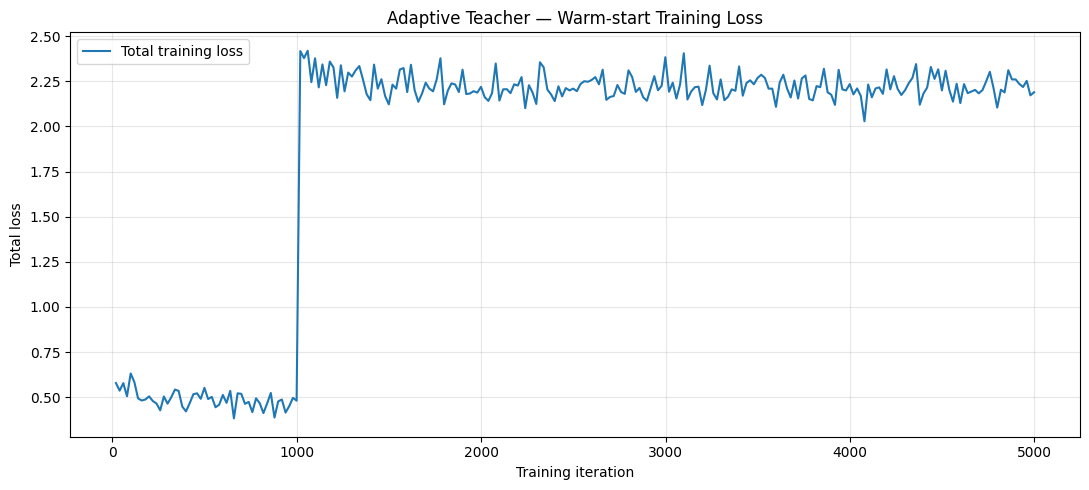

Loss records extracted: 250
Iteration range: 19–4999


In [12]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Uses the verified warm-start log from the previous cell
pattern = re.compile(
    r"\biter:\s*(\d+)\b.*?"
    r"\btotal_loss:\s*([\d.eE+-]+)"
)

records = [
    {"iteration": int(i), "total_loss": float(loss)}
    for i, loss in pattern.findall(warmstart_log)
]

loss_df = (
    pd.DataFrame(records)
    .drop_duplicates(subset="iteration")
    .sort_values("iteration")
)

if loss_df.empty:
    raise ValueError("No training-loss records found in the log.")

plt.figure(figsize=(11, 5))
plt.plot(
    loss_df["iteration"],
    loss_df["total_loss"],
    linewidth=1.5,
    label="Total training loss"
)

plt.xlabel("Training iteration")
plt.ylabel("Total loss")
plt.title("Adaptive Teacher — Warm-start Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Loss records extracted: {len(loss_df)}")
print(f"Iteration range: {loss_df.iteration.min()}–{loss_df.iteration.max()}")